<div style="max-width: 380px;">

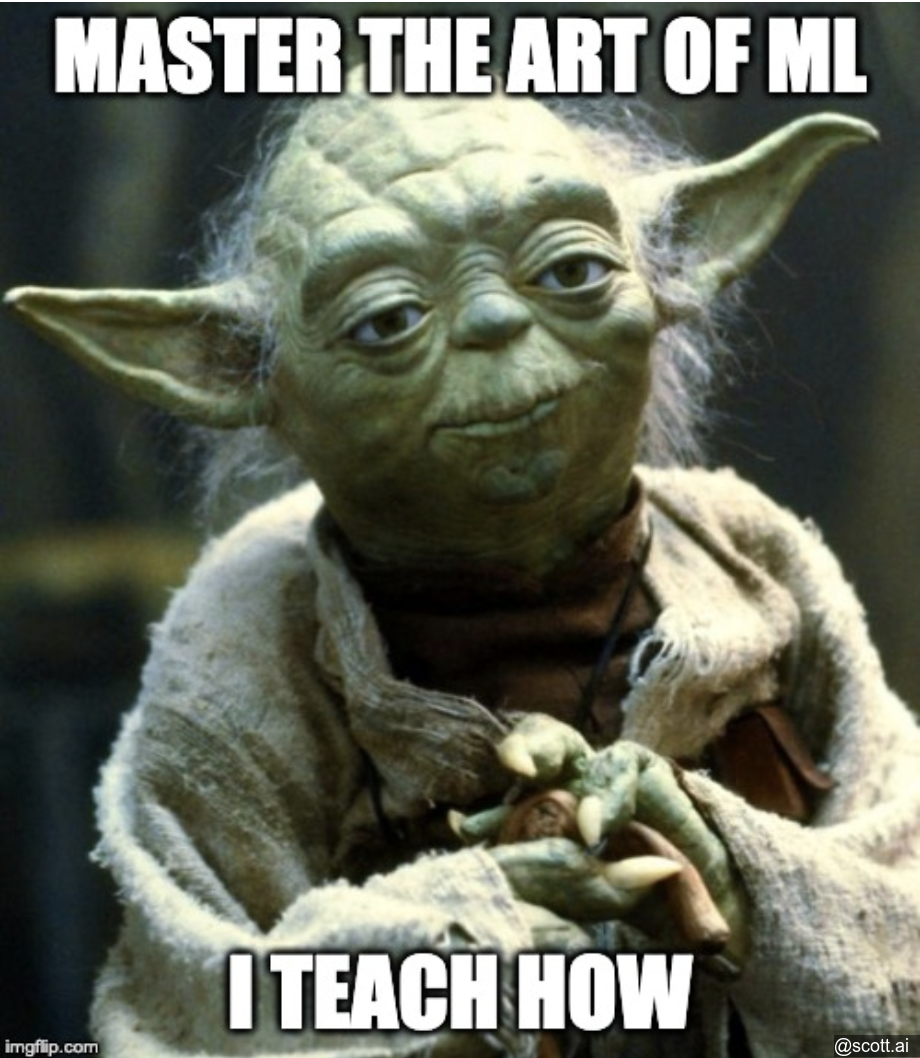

</div>

# 1. Problem and metrics
Flag suspicious payments for review in an intentionally easy synthetic dataset with clear risk profiles and light label noise.

In [1]:
from pathlib import Path
import os
import sys
import time
import json
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
started = time.perf_counter()

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from fraud.config import load_config
from fraud import plots
config = load_config()
plots.setup()

Precision is the fraction of alerts that are fraud. Recall is the fraction of fraud caught. PR-AUC here means average precision, a summary of the precision–recall curve across thresholds. Cost is missed fraud times its assumed cost plus false alarms times their assumed cost, divided by transaction count.

Accuracy counts all correct predictions, so the large legitimate class can hide missed fraud.

,accuracy,precision,recall,pr_auc,cost_per_txn
Always approve,0.9853,0.0,0.0,0.0147,44.0795


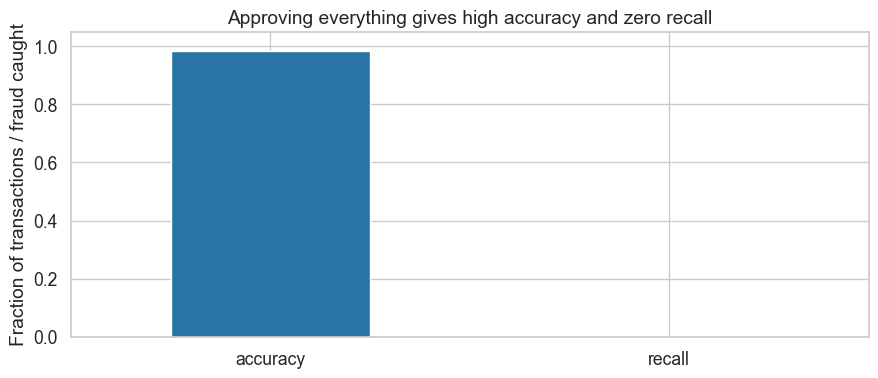

Always approving gets 98.53% accuracy but catches 0% of fraud in the training period. Assumed costs are INR 3,000 per missed fraud and INR 100 per false alarm.

In [3]:
from fraud.evaluate import metrics
raw = pd.read_csv('data/transactions.csv')
from fraud.cleaning import clean_data, time_split, split_summary
clean = clean_data(raw)
past = time_split(clean, config)[0]
approve = pd.DataFrame([metrics(past.is_fraud, np.zeros(len(past)), 0.5, config)], index=['Always approve'])
display(approve[['accuracy', 'precision', 'recall', 'pr_auc', 'cost_per_txn']].round(4))
plots.baseline_chart(approve)
display(Markdown(f'Always approving gets {approve.iloc[0].accuracy:.2%} accuracy but catches {approve.iloc[0].recall:.0%} of fraud in the training period. Assumed costs are INR {config["costs"]["missed_fraud"]:,} per missed fraud and INR {config["costs"]["false_alarm"]:,} per false alarm.'))

<div style="max-width: 360px;">

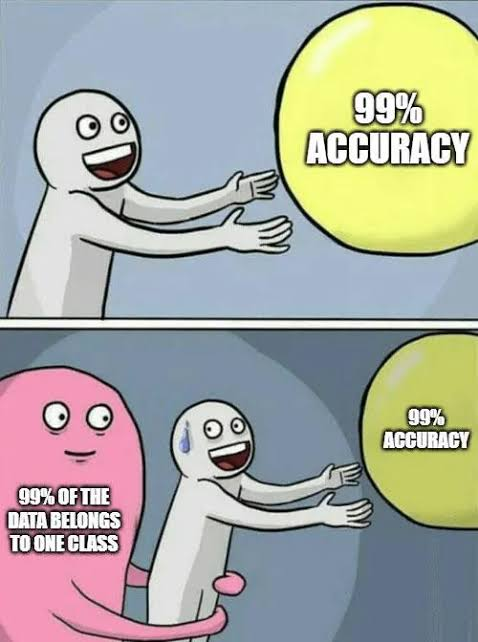

</div>

Illustration only: 99% is the meme's example; the table above gives this dataset's measured accuracy.

# 2. Load data
Inspect the one CSV table so its dimensions, types and memory use are explicit.

In [4]:
display(raw.head())
display(raw.dtypes.rename('dtype').to_frame())
display(Markdown(f'The raw table has {raw.shape[0]:,} rows and {raw.shape[1]} columns, using {raw.memory_usage(deep=True).sum() / 1024**2:.2f} MiB. Timestamps are strings until cleaning parses them.'))

,txn_id,timestamp,customer_id,amount_inr,merchant_category,city,distance_from_home_km,device_type,is_new_merchant,txns_last_1h,customer_avg_amount_inr,is_fraud
0,T000000,2025-01-01 00:00:10,4727,423.07,shopping,Bengaluru,0.31,mobile,1,0,279.47,0
1,T000001,2025-01-01 00:04:32,4494,704.99,fuel,Kolkata,1.37,mobile,1,0,597.36,0
2,T000002,2025-01-01 00:05:04,645,100.00,food,Chennai,1604.77,mobile,1,0,462.44,0
3,T000003,2025-01-01 00:08:28,4207,1217.98,grocery,Pune,1.13,pos_terminal,1,0,814.72,0
4,T000004,2025-01-01 00:08:39,645,368.64,electronics,Jaipur,2.68,pos_terminal,1,1,462.44,0


,dtype
txn_id,object
timestamp,object
customer_id,int64
amount_inr,float64
merchant_category,object
city,object
distance_from_home_km,float64
device_type,object
is_new_merchant,int64
txns_last_1h,int64


The raw table has 50,150 rows and 12 columns, using 18.55 MiB. Timestamps are strings until cleaning parses them.

# 3. Clean data
Remove duplicates and invalid amounts, standardise categories and use training-only imputation to avoid learning from future rows.

,missing_count,missing_percent
txn_id,0,0.000000
timestamp,0,0.000000
customer_id,0,0.000000
amount_inr,0,0.000000
merchant_category,0,0.000000
city,0,0.000000
distance_from_home_km,1257,2.506481
device_type,1003,2.000000
is_new_merchant,0,0.000000
txns_last_1h,0,0.000000


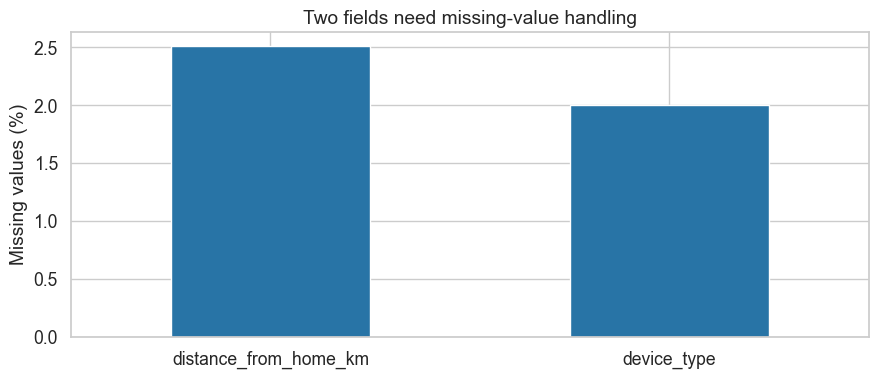

,before,after
rows,50150,49990
duplicates,150,0
invalid amounts,10,0
missing device,1003,0


Cleaning removes 160 rows; 1,250 distances remain missing until the pipeline learns a median from training rows. Missing devices become “unknown”; category spaces/case are normalised.

In [5]:
missing = pd.DataFrame({'missing_count': raw.isna().sum(), 'missing_percent': raw.isna().mean() * 100})
display(missing)
plots.missing_chart(raw)
summary = pd.DataFrame({'before': [len(raw), raw.duplicated().sum(), (raw.amount_inr <= 0).sum(), raw.device_type.isna().sum()], 'after': [len(clean), clean.duplicated().sum(), (clean.amount_inr <= 0).sum(), clean.device_type.isna().sum()]}, index=['rows', 'duplicates', 'invalid amounts', 'missing device'])
display(summary)
display(Markdown(f'Cleaning removes {len(raw)-len(clean):,} rows; {clean.distance_from_home_km.isna().sum():,} distances remain missing until the pipeline learns a median from training rows. Missing devices become “unknown”; category spaces/case are normalised.'))

In [6]:
training_median = past.distance_from_home_km.median()
imputed_preview = clean[['distance_from_home_km', 'device_type']].copy()
imputed_preview['distance_from_home_km'] = imputed_preview.distance_from_home_km.fillna(training_median)
display(imputed_preview.head())
display(Markdown(f'This preview uses the training-period median of {training_median:.2f} km and has {imputed_preview.isna().sum().sum():,} missing cells. The actual model repeats imputation inside its fitted pipeline; hour and day_of_week come directly from timestamps.'))

,distance_from_home_km,device_type
0,0.31,mobile
1,1.37,mobile
2,1604.77,mobile
3,1.13,pos_terminal
4,2.68,pos_terminal


This preview uses the training-period median of 4.00 km and has 0 missing cells. The actual model repeats imputation inside its fitted pipeline; hour and day_of_week come directly from timestamps.

# 4. EDA
Use only the first 60 days for these five exploratory figures so the final test period remains untouched.

Count labels to show imbalance.

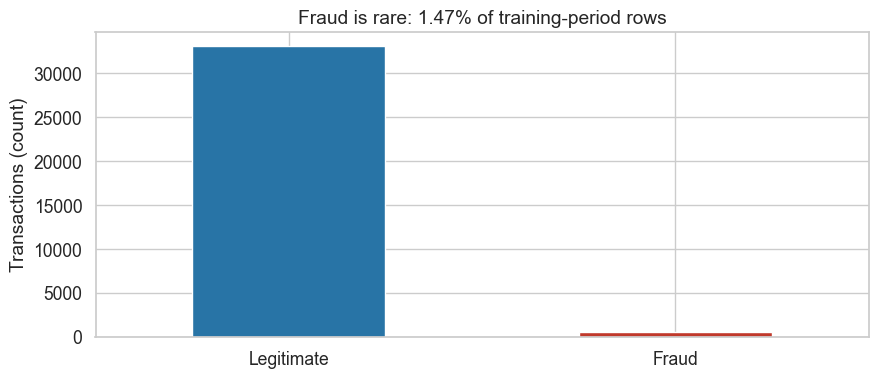

Only 493 of 33,553 training-period transactions are fraud.

In [7]:
display(Markdown(plots.eda_chart(past, 1, config)))

Compare hours to motivate is_night.

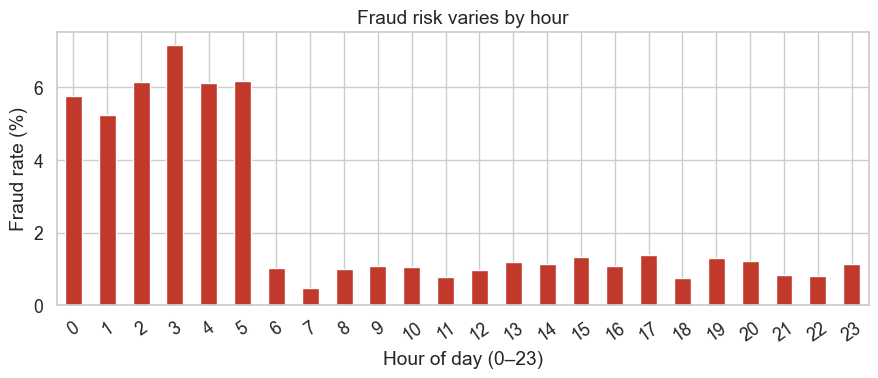

Night-time fraud rate is 6.10%, compared with 1.02% at other hours.

In [8]:
display(Markdown(plots.eda_chart(past, 2, config)))

Compare amounts and their tail to motivate amount_to_avg_ratio and log_amount.

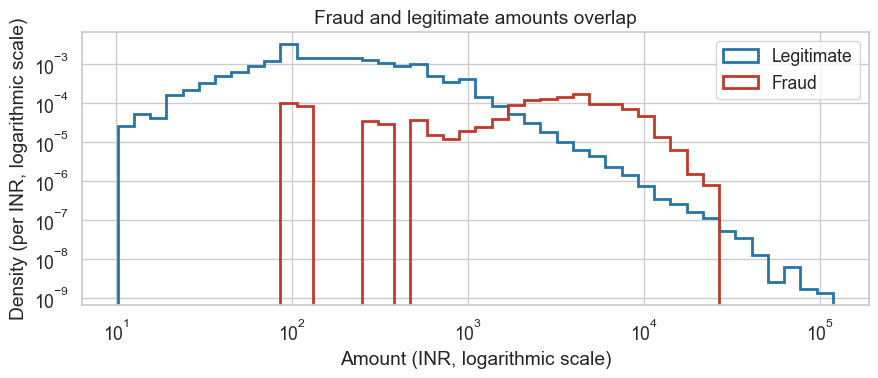

Median amount/usual-spend ratio is 10.87 for fraud and 0.81 for legitimate payments; log amount compresses the long tail.

In [9]:
display(Markdown(plots.eda_chart(past, 3, config)))

Compare categories and devices to inspect categorical risk.

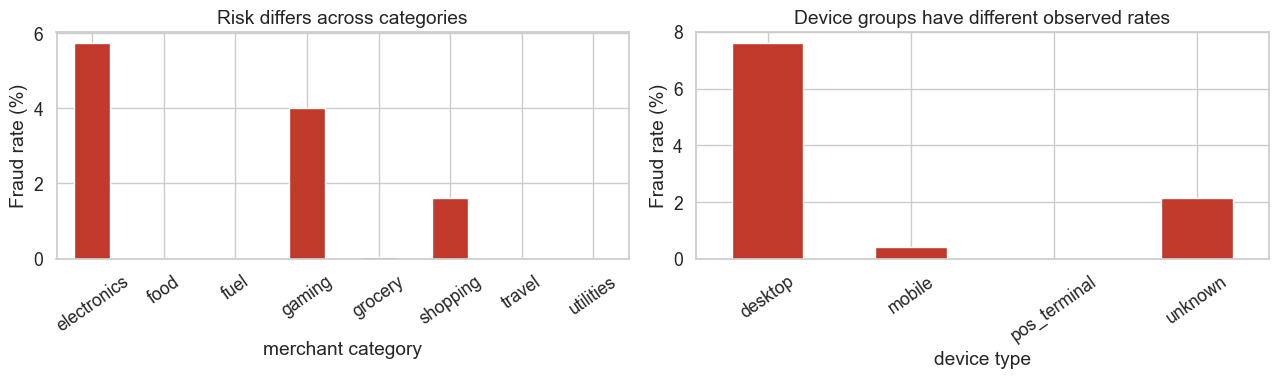

electronics has the highest observed category fraud rate, 5.75%.

In [10]:
display(Markdown(plots.eda_chart(past, 4, config)))

Compare distance and merchant familiarity to motivate is_far_from_home.

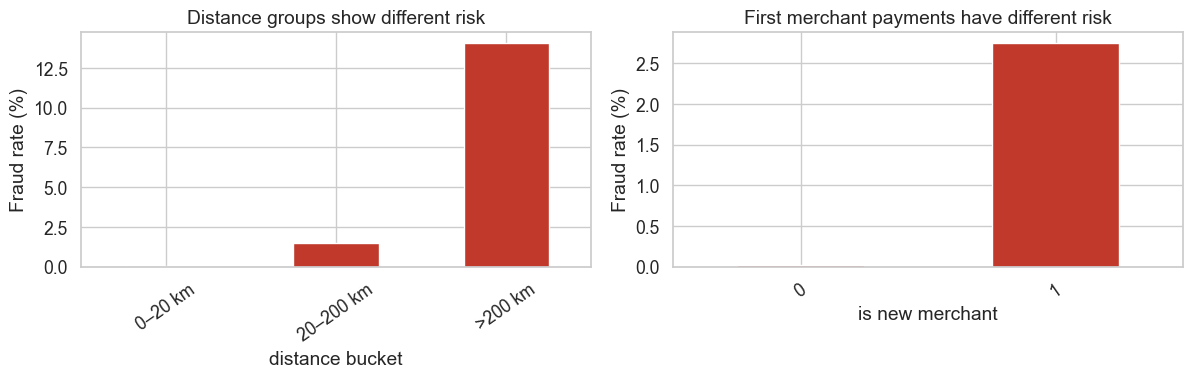

Fraud rate beyond 200 km is 14.07%; new-merchant payments have 2.75% fraud.

In [11]:
display(Markdown(plots.eda_chart(past, 5, config)))

# 5. Feature engineering
Add four row-local features to express the time, relative amount and distance patterns seen in EDA.

In [12]:
from fraud.features import add_features, BASE_NUMERIC, ENGINEERED, CATEGORICAL, FEATURES
featured = add_features(clean, config)
display(pd.DataFrame({'feature': ENGINEERED, 'reason': ['Hour chart: before 06:00', 'Amount chart: spend relative to customer usual amount', 'Distance chart: more than configured 200 km', 'Amount chart: compress the long right tail']}))
print('Before:', BASE_NUMERIC + CATEGORICAL)
print('After: ', FEATURES)
display(featured[ENGINEERED].head())
display(Markdown(f'The feature set grows from {len(BASE_NUMERIC+CATEGORICAL)} to {len(FEATURES)} inputs; IDs and the raw timestamp are excluded. No feature uses the fraud label or future transactions.'))

,feature,reason
0,is_night,Hour chart: before 06:00
1,amount_to_avg_ratio,Amount chart: spend relative to customer usual...
2,is_far_from_home,Distance chart: more than configured 200 km
3,log_amount,Amount chart: compress the long right tail


Before: ['amount_inr', 'distance_from_home_km', 'is_new_merchant', 'txns_last_1h', 'customer_avg_amount_inr', 'hour', 'day_of_week', 'merchant_category', 'city', 'device_type']
After:  ['amount_inr', 'distance_from_home_km', 'is_new_merchant', 'txns_last_1h', 'customer_avg_amount_inr', 'hour', 'day_of_week', 'is_night', 'amount_to_avg_ratio', 'is_far_from_home', 'log_amount', 'merchant_category', 'city', 'device_type']


,is_night,amount_to_avg_ratio,is_far_from_home,log_amount
0,1,1.513830,0.0,6.049899
1,1,1.180176,0.0,6.559601
2,1,0.216244,1.0,4.615121
3,1,1.494968,0.0,7.105770
4,1,0.797163,0.0,5.912530


The feature set grows from 10 to 14 inputs; IDs and the raw timestamp are excluded. No feature uses the fraud label or future transactions.

# 6. Train/validation/test split
we train on the past and test on the future, like real life

A random split can be too optimistic because it mixes earlier and later behaviour; this synthetic dataset does not establish how large that effect would be in production.

,split,rows,start,end,fraud_rate
0,train,33553,2025-01-01 00:00:10,2025-03-01 23:59:54,0.014693
1,validation,8283,2025-03-02 00:01:59,2025-03-16 23:58:00,0.016419
2,test,8154,2025-03-17 00:07:20,2025-03-31 23:57:37,0.014104


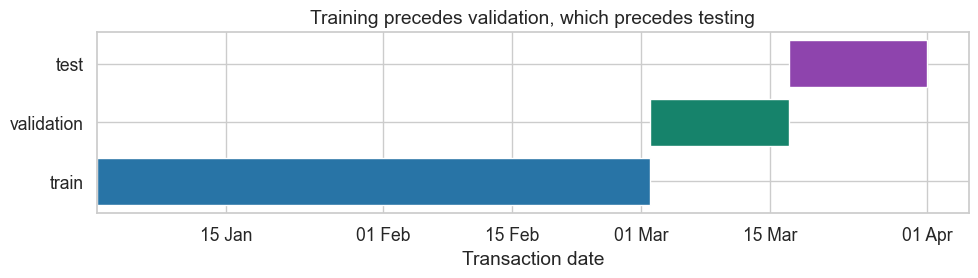

The split contains 33,553 training, 8,283 validation and 8,154 test rows across 60/15/15 calendar days. The train fraud rate is 1.47% versus 1.64% in validation.

In [13]:
train, validation, test = time_split(featured, config)
balance = split_summary((train, validation, test))
display(balance)
plots.timeline(balance)
display(Markdown(f'The split contains {len(train):,} training, {len(validation):,} validation and {len(test):,} test rows across 60/15/15 calendar days. The train fraud rate is {train.is_fraud.mean():.2%} versus {validation.is_fraud.mean():.2%} in validation.'))

# 7. Preprocessing pipeline and models
Fit one preprocessing-and-model pipeline per estimator on training rows only, using class weights to address imbalance.

In [14]:
from fraud.models import fit_models, select_model, train_validation_scores, importance, save_bundle
bundles, comparison = fit_models(train, validation, config)
display(bundles['Logistic Regression']['pipeline'])
display(comparison[['train_seconds', 'threshold']].round(3))
display(Markdown(f'Three learned models plus the baseline fit in {comparison.train_seconds.sum():.2f} seconds. Numeric medians and categorical one-hot vocabularies are learned on training data; only logistic regression also scales numeric inputs.'))

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


,train_seconds,threshold
model,,
Always approve,0.094,0.01
Logistic Regression,0.135,0.85
Random Forest,1.065,0.60
LightGBM,0.250,0.79


Three learned models plus the baseline fit in 1.54 seconds. Numeric medians and categorical one-hot vocabularies are learned on training data; only logistic regression also scales numeric inputs.

Logistic regression fits an additive decision rule, random forest averages small decision trees, and LightGBM adds trees that correct earlier errors. No hyperparameter search is used; validation chooses thresholds on the same fixed grid, requiring at least 85% precision where achievable.

# 8. Metrics
Compare models on the same validation period at their cost-minimising thresholds within the daily review budget and precision target, where achievable.

,threshold,train_seconds,accuracy,precision,recall,f1,pr_auc,roc_auc,cost_per_txn,alerts
model,,,,,,,,,,
Always approve,0.01,0.0939,0.9836,0.0000,0.0000,0.0000,0.0164,0.5000,49.2575,0
Logistic Regression,0.85,0.1350,0.9961,0.8611,0.9118,0.8857,0.9346,0.9736,4.5877,144
Random Forest,0.60,1.0654,0.9987,0.9630,0.9559,0.9594,0.9500,0.9838,2.2335,135
LightGBM,0.79,0.2502,0.9987,0.9630,0.9559,0.9594,0.9182,0.9751,2.2335,135


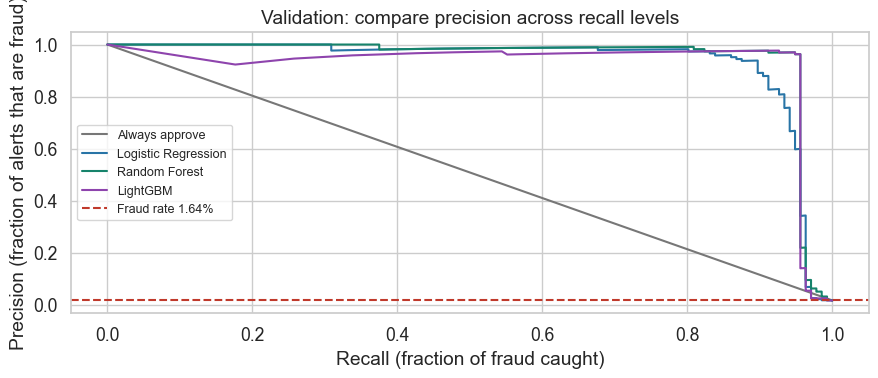

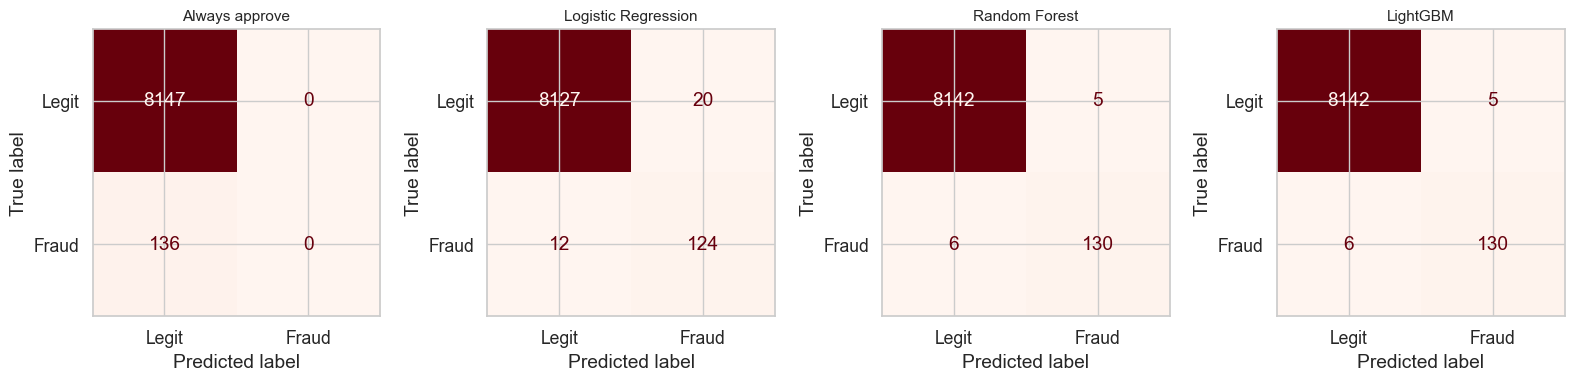

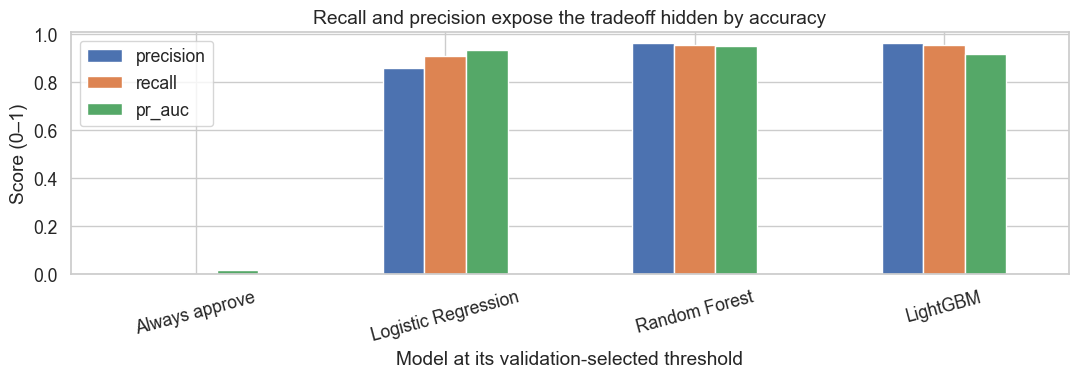

Random Forest has the highest validation PR-AUC (0.950), against a fraud-rate reference of 0.016. Threshold-dependent metrics use the same assumed costs and review budget.

In [15]:
display(comparison.round(4))
probabilities = {name: bundle['pipeline'].predict_proba(validation[FEATURES])[:, 1] for name, bundle in bundles.items()}
thresholds = {name: bundle['threshold'] for name, bundle in bundles.items()}
plots.pr_curves(validation.is_fraud, probabilities, 'Validation: compare precision across recall levels')
plots.confusion(validation.is_fraud, probabilities, thresholds)
plots.metric_bars(comparison)
best_ap = comparison.pr_auc.idxmax()
display(Markdown(f'{best_ap} has the highest validation PR-AUC ({comparison.loc[best_ap, "pr_auc"]:.3f}), against a fraud-rate reference of {validation.is_fraud.mean():.3f}. Threshold-dependent metrics use the same assumed costs and review budget.'))

In [16]:
overfit = train_validation_scores(bundles, train, validation, config)
display(overfit.round(4))
gaps = overfit.train_pr_auc - overfit.validation_pr_auc
largest_gap = gaps.idxmax()
display(Markdown(f'{largest_gap} has the largest train-minus-validation PR-AUC gap ({gaps[largest_gap]:.3f}). A positive gap is a warning about overfitting or changed data, rather than proof of its cause.'))

,train_pr_auc,train_recall,validation_pr_auc,validation_recall
model,,,,
Always approve,0.0147,0.0000,0.0164,0.0000
Logistic Regression,0.9263,0.9757,0.9346,0.9118
Random Forest,0.9802,0.9858,0.9500,0.9559
LightGBM,0.9747,1.0000,0.9182,0.9559


LightGBM has the largest train-minus-validation PR-AUC gap (0.057). A positive gap is a warning about overfitting or changed data, rather than proof of its cause.

# 9. Choose model and threshold
Select the lowest validation cost among models meeting the quality gate and daily review budget, breaking cost ties by higher PR-AUC.

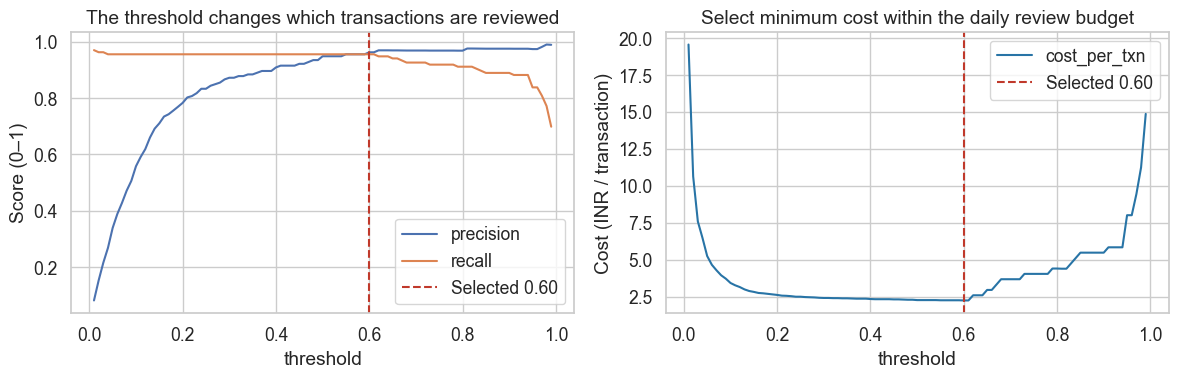

Selected Random Forest at threshold 0.60 because it meets the quality gate with the lowest validation cost (ties use PR-AUC), INR 2.23 per transaction, with recall 95.59% and precision 96.30%. Its busiest validation day has 16 alerts, within the assumed budget of 45 per day.

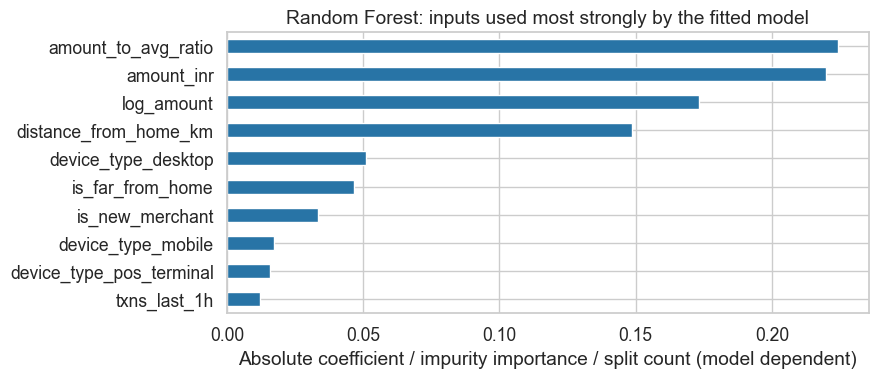

The largest built-in importance belongs to amount_to_avg_ratio. Importance describes this fitted model, not a causal effect.

In [17]:
selected = select_model(bundles, comparison, config)
name, threshold = selected['name'], selected['threshold']
plots.threshold_plot(selected['curve'], threshold)
row = comparison.loc[name]
peak = selected['curve'].loc[np.isclose(selected['curve'].threshold, threshold), 'peak_alerts_per_day'].iloc[0]
display(Markdown(f'Selected {name} at threshold {threshold:.2f} because it meets the quality gate with the lowest validation cost (ties use PR-AUC), INR {row.cost_per_txn:.2f} per transaction, with recall {row.recall:.2%} and precision {row.precision:.2%}. Its busiest validation day has {peak:.0f} alerts, within the assumed budget of {config["alert_budget_per_day"]} per day.'))
plots.importance_chart(importance(selected), name)
display(Markdown(f'The largest built-in importance belongs to {importance(selected).index[-1]}. Importance describes this fitted model, not a causal effect.'))

# 10. Final test and next steps
Evaluate the frozen model and threshold once on the held-out final 15 days to estimate performance on later transactions.

,accuracy,precision,recall,f1,pr_auc,roc_auc,cost_per_txn,alerts
validation,0.9987,0.9630,0.9559,0.9594,0.9500,0.9838,2.2335,135.0
test,0.9983,0.9106,0.9739,0.9412,0.9377,0.9854,1.2387,123.0


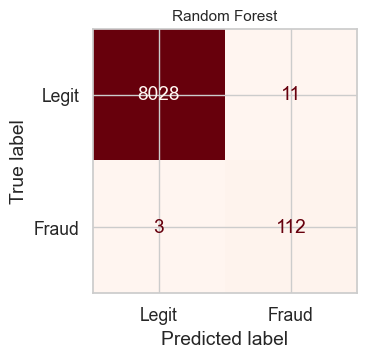

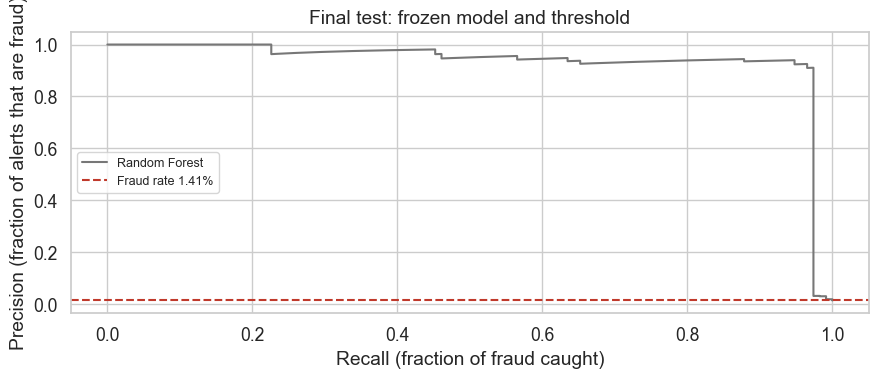

Test recall is 97.39%, precision 91.06%, PR-AUC 0.938, and cost INR 1.24 per transaction. Test cost differs from validation by INR -0.99; no threshold is changed after this result.

In [18]:
test_probability = selected['pipeline'].predict_proba(test[FEATURES])[:, 1]
test_metrics = metrics(test.is_fraud, test_probability, threshold, config)
final = pd.DataFrame({'validation': selected['validation_metrics'], 'test': test_metrics}).T
display(final.round(4))
plots.confusion(test.is_fraud, {name: test_probability}, {name: threshold})
plots.pr_curves(test.is_fraud, {name: test_probability}, 'Final test: frozen model and threshold')
save_bundle(selected, ROOT / 'models' / 'candidate.joblib')
save_bundle(bundles['Always approve'], ROOT / 'models' / 'baseline.joblib')
display(Markdown(f'Test recall is {test_metrics["recall"]:.2%}, precision {test_metrics["precision"]:.2%}, PR-AUC {test_metrics["pr_auc"]:.3f}, and cost INR {test_metrics["cost_per_txn"]:.2f} per transaction. Test cost differs from validation by INR {test_metrics["cost_per_txn"]-row.cost_per_txn:+.2f}; no threshold is changed after this result.'))

In [19]:
elapsed = time.perf_counter() - started
report = {'selected_model': name, 'threshold': threshold, 'data_version': config['data']['version'], 'comparison': comparison.reset_index().to_dict('records'), 'test': test_metrics, 'validation': selected['validation_metrics'], 'notebook_body_seconds': elapsed}
(ROOT / 'models' / 'ml_summary.json').write_text(json.dumps(report, indent=2))
display(Markdown(f'Saved the fitted pipeline and threshold in models/candidate.joblib; this notebook body ran in {elapsed:.2f} seconds on this machine. These results come from intentionally clear synthetic patterns; light label noise keeps the example imperfect.'))

Saved the fitted pipeline and threshold in models/candidate.joblib; this notebook body ran in 6.49 seconds on this machine. These results come from intentionally clear synthetic patterns; light label noise keeps the example imperfect.

**Limitations and next steps**

- Synthetic data: clear risk profiles and light label noise were designed for teaching; scores do not establish real-world performance.
- More features: evaluate better transaction context on real, consented data.
- Drift monitoring: check whether incoming data changes.
- Delayed labels: account for when confirmed fraud becomes available.
- Explainability: validate explanations with fraud reviewers.
- Retraining: define when a new candidate should be trained and reviewed.